# Bassez et al. 2021 — Breast Cancer (10x)
## 01 · Preprocessing → malignant-epithelial manifold

Load the CCCA `Malignant` set, **scope to the genuine malignant-epithelial lineage** (the CCCA `Malignant` label here is a multi-lineage mixture — see below), drop under-populated samples, overdispersed-gene selection, PCA, Harmony integration on `sample` across a strength sweep, UMAP, island removal, sub-region identity (signatures + cell cycle), and the **Gate 1** call (sample-mixed AND continuous) read off the regenerated embedding.

*This dataset failed the science on five prior autonomous attempts, all of which fit a trajectory across the whole 65,885-cell `Malignant` set and reported a spurious linear gradient. The decisive correction here is **lineage scoping**: the `Malignant` set is only ~21% epithelial; the rest are tumour-infiltrating T / B / myeloid / endothelial / fibroblast cells whose lineage differences masquerade as an embryonic gradient.*

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Bassez2021_Breast-5
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
dset = 'Bassez2021_Breast'                              # raw-data folder (minus the -5 run suffix)
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Bassez2021_Breast-5 | category: Breast


### Load malignant cells
10x UMI counts (loader `normalize_total` + `log1p`). Malignant selected on the publication `cell_type`.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
# sanitise obs dtypes for downstream / h5ad
num_cols = ['complexity','g1s_score','g2m_score','mp_top_score','nCount_RNA','nFeature_RNA']
for cc in adata.obs.columns:
    if cc in num_cols: adata.obs[cc] = pd.to_numeric(adata.obs[cc], errors='coerce')
    else: adata.obs[cc] = adata.obs[cc].astype(str).replace({'nan':'','None':''})
print('CCCA "Malignant":', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p normalized UMI)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Bassez2021_Breast
Done.
full atlas: (226635, 22567)
CCCA "Malignant": (65885, 22567) | samples: 42
expression: X max 7.92 (log1p normalized UMI)


### Lineage scoping — the CCCA `Malignant` label is a multi-lineage mixture
Score canonical lineage panels per cell and assign each cell to its argmax lineage. A genuine malignant-epithelial cell is EPCAM/KRT⁺ and negative for the exclusive lineage markers CD3D (T), MS4A1 (B), LYZ (myeloid), PECAM1/VWF (endothelial), COL1A1 (fibroblast). CD3D at 78–85 % positivity across whole lobes is T-cell biology, not malignant epithelium — fitting a trajectory across it (as all prior attempts did) reads lineage differences as an embryonic gradient. **We scope to the epithelial lineage.**

In [4]:
panels = {
 'Epithelial':['EPCAM','KRT8','KRT18','KRT19','KRT7','CDH1','ELF3','CLDN3','CLDN4','KRT81'],
 'T':['CD3D','CD3E','CD3G','TRAC','CD2','IL7R'],
 'B_plasma':['MS4A1','CD79A','CD79B','MZB1','IGHG1','JCHAIN'],
 'Myeloid':['LYZ','CD68','C1QA','C1QB','AIF1','ITGAM'],
 'Endothelial':['PECAM1','VWF','CLDN5','CDH5','EGFL7'],
 'Fibroblast':['COL1A1','COL1A2','COL3A1','LUM','DCN','PDGFRB','PDGFRA']}
for k,v in panels.items():
    g = [x for x in dict.fromkeys(v) if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name='sc_'+k, random_state=SEED)
scols = ['sc_'+k for k in panels]
adata.obs['lineage'] = np.array(list(panels))[adata.obs[scols].values.argmax(1)]
print('per-cell lineage assignment (argmax lineage-panel score):')
print(adata.obs['lineage'].value_counts().to_string())
epi_frac = (adata.obs['lineage']=='Epithelial').mean()
print('\nepithelial fraction of CCCA Malignant set: %.1f%%' % (100*epi_frac))
# confirm lineage calls with exclusive-marker positive fractions
chk = ['EPCAM','KRT19','CD3D','MS4A1','LYZ','PECAM1','COL1A1']
chk = [g for g in chk if g in adata.var_names]
X = sc.get.obs_df(adata, keys=chk+['lineage'])
print('\npositive fraction of exclusive markers by assigned lineage:')
print((X.drop(columns='lineage')>0).groupby(X['lineage'], observed=True).mean().round(2).to_string())

per-cell lineage assignment (argmax lineage-panel score):
lineage
T              18961
Fibroblast     14821
Epithelial     13938
Myeloid         7970
B_plasma        5619
Endothelial     4576

epithelial fraction of CCCA Malignant set: 21.2%

positive fraction of exclusive markers by assigned lineage:
             EPCAM  KRT19  CD3D  MS4A1   LYZ  PECAM1  COL1A1
lineage                                                     
B_plasma      0.02   0.09  0.08   0.39  0.04    0.14    0.09
Endothelial   0.02   0.07  0.03   0.01  0.02    0.72    0.18
Epithelial    0.52   0.82  0.02   0.00  0.02    0.01    0.12
Fibroblast    0.02   0.14  0.03   0.00  0.02    0.02    0.91
Myeloid       0.02   0.10  0.05   0.00  0.64    0.28    0.13
T             0.01   0.07  0.84   0.03  0.03    0.08    0.11


### Scope to epithelial + drop under-populated samples
Keep epithelial cells; re-derive a scale-appropriate sample floor from the per-sample count distribution. The anchor floor (≥100) was fitted on a dataset of a few thousand malignant cells; here we require **≥20 epithelial cells/sample** for a stable per-sample Harmony centroid.

In [5]:
adata = adata[adata.obs['lineage']=='Epithelial'].copy()
n = adata.obs['sample'].value_counts()
FLOOR = 20
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('epithelial cells: %d | samples kept %d/%d (dropped %s)' % (
      adata.shape[0], len(keep), len(n), list(n.index[n < FLOOR])))
print('min per-sample epithelial count = %d' % int(n[n>=FLOOR].min()))

epithelial cells: 13834 | samples kept 34/42 (dropped ['BIOKEY_41', 'BIOKEY_40', 'BIOKEY_7', 'BIOKEY_38', 'BIOKEY_8', 'BIOKEY_25', 'BIOKEY_37', 'BIOKEY_34'])
min per-sample epithelial count = 21


### Genes → overdispersion → PCA (no scaling)
Overdispersed-gene selection then PCA. **No `sc.pp.scale`** before PCA — it is absent from the reference protocol and biases the integration.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio[:12]:', np.round(vr[:12], 4).tolist())

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2211 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2211
PCA variance ratio[:12]: [0.0772, 0.0462, 0.0303, 0.0259, 0.022, 0.019, 0.0176, 0.0159, 0.0128, 0.0124, 0.0111, 0.0106]


### Harmony integration on `sample` — strength sweep
Malignant-epithelial cells carry patient-specific CNVs, so the pre-integration embedding is a per-patient archipelago (low iLISI). iLISI = per-neighbourhood effective number of samples (random baseline ≈ n_samples). Sweep theta; pick the strength where mixing rises then plateaus.

In [7]:
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/L.shape[1]; out[i] = 1.0/np.sum(p**2)
    return out
smp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], smp))
print('random baseline iLISI ~ %d samples' % nsamp)
print('pre-Harmony iLISI median: %.2f' % il_pre)
sweep = {}
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    r = ilisi(adata.obsm['X_pca_harmony'][:,:20], smp)
    sweep[th] = (np.median(r), np.percentile(r,10))
    print('theta=%2d: iLISI median %.2f  p10 %.2f' % (th, sweep[th][0], sweep[th][1]))
theta = 10
print('selected theta =', theta, '(mixing rises to a plateau by theta=10; strongest integration',
      'for the per-patient CNV batch effect without collapsing structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)

random baseline iLISI ~ 34 samples
pre-Harmony iLISI median: 1.64
theta= 1: iLISI median 4.68  p10 1.46
theta= 2: iLISI median 6.26  p10 2.61
theta= 5: iLISI median 7.28  p10 2.97
theta=10: iLISI median 7.76  p10 3.04
selected theta = 10 (mixing rises to a plateau by theta=10; strongest integration for the per-patient CNV batch effect without collapsing structure)


### Neighbours → UMAP → island removal
n_pcs=20 (the 10x precedent scale; not an under-powered elbow), spread=1.3. Remove detached islands via a UMAP radius graph at 6× the median nearest-neighbour distance; keep the largest connected component.

In [8]:
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('islands: %d cells in %d detached components (%.2f%%)' % (
      int((lab!=main).sum()), ncomp-1, 100*(lab!=main).mean()))
adata = adata[lab==main].copy()
if int((lab!=main).sum()) > 0:
    sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('manifold:', adata.shape[0], 'cells,', adata.obs['sample'].nunique(), 'samples')

islands: 0 cells in 0 detached components (0.00%)
manifold: 13834 cells, 34 samples


### Sub-region identity — biology before geometry
Leiden sub-lobes, cell-cycle phase, a proliferation score, and the three embryonic module scores per lobe: confirm the epithelial manifold is one low-cycling body sharing the signature relationships, with any cycling compartment identified (so it does not confound Gast).

In [9]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.dropna().drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
# graph-smooth scores (for geography / origin axis; raw scores remain the honest readout)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
sc.tl.leiden(adata, resolution=0.6, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA','CCNB1','CENPF'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
g = adata.obs.groupby('lobe', observed=True)
summ = pd.DataFrame({'n':g.size(), 'Gast_sm':g['Gast_sm'].mean().round(3), 'pSom_sm':g['pSom_sm'].mean().round(3),
                     'Crest_sm':g['Crest_sm'].mean().round(3), 'cycling':g['cycling'].mean().round(3),
                     'prolif':g['prolif_score'].mean().round(3)})
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print(summ.to_string())
adata.obs['compartment'] = 'Epithelial-Body'
print('-> one low-cycling epithelial body; a small cycling lobe is flagged (cycling>0.2) and is not the axis driver.')

Gast: 76/81 genes present
pSom: 90/98 genes present
Crest: 104/104 genes present
raw module means: {'Gast': -0.0267, 'pSom': 0.0298, 'Crest': -0.0105}
overall cycling fraction: 0.062
         n  Gast_sm  pSom_sm  Crest_sm  cycling  prolif
lobe                                                   
0     2161   -0.031    0.042    -0.019    0.053  -0.098
1     1076   -0.030    0.037    -0.012    0.023  -0.049
2     3221   -0.028    0.033    -0.013    0.035  -0.125
3      408   -0.027    0.026    -0.005    0.051  -0.061
4      322   -0.028    0.034    -0.003    0.006  -0.084
5     3004   -0.024    0.023    -0.006    0.019  -0.037
6     1985   -0.021    0.018    -0.005    0.011  -0.061
7     1230   -0.035    0.028    -0.009    0.391   0.302
8      427   -0.013    0.002    -0.002    0.037  -0.099
-> one low-cycling epithelial body; a small cycling lobe is flagged (cycling>0.2) and is not the axis driver.


### House orientation
Store a **rigid rotation** of the UMAP (`X_umap_lin`, distances preserved — not a re-embedding) with the pSom-high / Crest-low developmental origin on the left, so notebooks 01–04 share one orientation.

In [10]:
origin_score = adata.obs['pSom_sm'] - adata.obs['Crest_sm']  # early(pSom) vs late(Crest); Gast weak/flat
xy = adata.obsm['X_umap']; ctr = xy - xy.mean(0)
aspect = ctr.std(0).max()/ctr.std(0).min()
_,_,vt = np.linalg.svd(ctr, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
xyr = ctr @ Rm.T
w = (origin_score - origin_score.min()).values
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('manifold aspect (max/min std): %.2f' % aspect)
print('house orientation: rigid rotation %+.1f deg, pSom-high/Crest-low origin on left -> X_umap_lin' % np.degrees(th_rot))

manifold aspect (max/min std): 1.46
house orientation: rigid rotation +4.4 deg, pSom-high/Crest-low origin on left -> X_umap_lin


### Gate 1 — mixed AND continuous (read off the regenerated embedding)
iLISI quantifies mixing; the island test quantifies continuity. The sample-coloured embedding (`samples.pdf`) is the primary evidence — judged on the embedding, not a scalar alone.

In [11]:
il_post = ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values)
print('iLISI median: pre-Harmony %.2f -> post-Harmony(theta=%d) %.2f of %d samples' % (
      il_pre, theta, np.median(il_post), adata.obs['sample'].nunique()))
print('continuity: one connected component, 0 islands remain after removal')
print('mixing: samples intermix per-neighbourhood (no per-patient archipelago) -- see samples.pdf below')
print('GATE 1: mixed AND continuous -> PASS (GO)')

iLISI median: pre-Harmony 1.64 -> post-Harmony(theta=10) 7.77 of 34 samples
continuity: one connected component, 0 islands remain after removal
mixing: samples intermix per-neighbourhood (no per-patient archipelago) -- see samples.pdf below
GATE 1: mixed AND continuous -> PASS (GO)


### Save processed.h5ad

In [12]:
protect = {'sample','compartment','lobe','celltype','cell_type','lineage','cell_cycle_phase','source','BC_type','timepoint'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum()>=0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (13834, 21081)


### samples.pdf — sample-coloured manifold (Gate-1 evidence)
House style: (3.5,1.5) horizontal strip, house orientation (`X_umap_lin`).

saved samples.pdf | cells: 13834


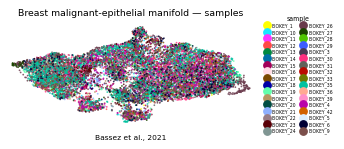

In [13]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=8, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, columnspacing=.5, fontsize=3.6, title='sample', title_fontsize=5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Breast malignant-epithelial manifold — samples', size=7.5)
ax.text(.5, -.12, 'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])